# Description 

TDC data from voxel volume : 0.125 bohr$^{3}$ for chromophores of PSI (7DKZ)

## Analysis :

Coulombic interaction from TDC 

### Scheme 

Load $V_{TDC}$ data, which is in Hartree (atomic units), then convert to wavenumber.

Next, use $\delta_{D \rightarrow A}$ , to obtain rates.

Lastly, convert rates to lifetimes, and then scale.

In [1]:
import os.path
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
import matplotlib

import seaborn as sns
import matplotlib.colors as colors

######################################################
 
import pandas as pd

-----------------------

-----------------

In [2]:
# load VTDC file (pkl file from a prior python calc)

vtdc_final =  pd.read_pickle('./TDC_calc_output/voxel_v_0.216/vtdc_0.216b3_.pkl')  # values in atomic units


---------------------

--------------------

--------------------------------------

## Plotting V values

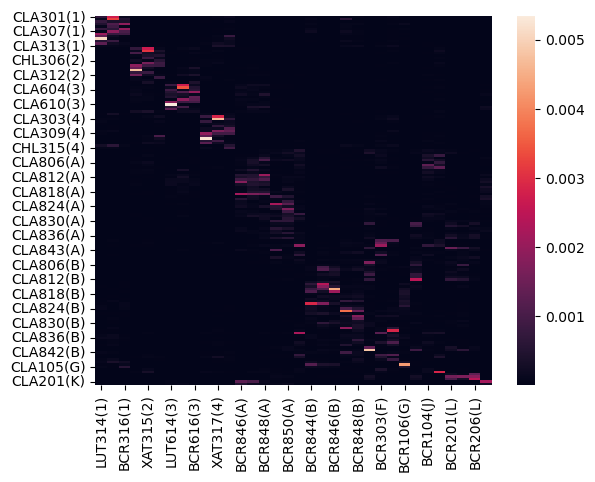

In [3]:


ax = sns.heatmap( np.abs(vtdc_final) 

                  
                   )

------------------

--------------------------

# Unit conversion and computation of rates

In [4]:
# perform unit conversion

import scipy.constants as const

V_au = vtdc_final
V_cm = V_au * 219474.63136314   # Hartree to wavenumber

hc_cm = const.h * const.c * 100.0      # J·cm

# Define scalar b values based on index prefix (chl-a and chl-b have different values)
#  this the rows have different values based on donor

delta_factors = np.where(V_cm.index.str.startswith("CLA"), 1.48047e-04 , 1.46000e-04) 

# Expand b_series to match DataFrame dimensions for broadcast multiplication
delta_mat = np.tile(delta_factors[:, None], (1, V_cm.shape[1]))


In [5]:
rate  = (2*np.pi/const.hbar) * (V_cm**2) * hc_cm * delta_mat

lifetime=1/rate   # This is unscaled.

target_lifetimes_ps = lifetime * 1e12  



------------------

-------------------------

-----------------------

## Plotting lifetimes in ps

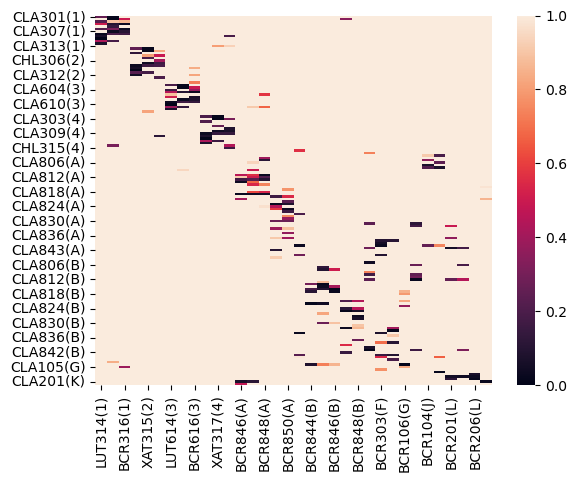

In [6]:
ax = sns.heatmap( target_lifetimes_ps,

                 vmin=0,
                 vmax= 1  )

------------------